In [1]:
from pathlib import Path

DATASET_ROOT = Path("/kaggle/input/competitions/aptos2019-blindness-detection")

print("Dataset contents:\n")

for path in DATASET_ROOT.iterdir():
    print(path.name)

Dataset contents:

sample_submission.csv
train_images
train.csv
test.csv
test_images


In [2]:
import pandas as pd

TRAIN_CSV = DATASET_ROOT / "train.csv"

train_df = pd.read_csv(TRAIN_CSV)

print("Training dataset shape:", train_df.shape)
print("\nColumns:")
print(train_df.columns.tolist())

print("\nFirst 5 rows:")
display(train_df.head())

print("\nData types:")
print(train_df.dtypes)

Training dataset shape: (3662, 2)

Columns:
['id_code', 'diagnosis']

First 5 rows:


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0



Data types:
id_code      object
diagnosis     int64
dtype: object


In [3]:
# Count images in each DR severity class
class_counts = train_df["diagnosis"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Diagnosis": class_counts.index,
    "Class_Name": [
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative DR"
    ],
    "Image_Count": class_counts.values,
    "Percentage": (
        class_counts.values / len(train_df) * 100
    ).round(2)
})

display(class_distribution)

print("Total training images:", class_counts.sum())
print("Number of classes:", train_df["diagnosis"].nunique())
print("Missing labels:", train_df["diagnosis"].isna().sum())

,Diagnosis,Class_Name,Image_Count,Percentage
0,0,No DR,1805,49.29
1,1,Mild,370,10.10
2,2,Moderate,999,27.28
3,3,Severe,193,5.27
4,4,Proliferative DR,295,8.06


Total training images: 3662
Number of classes: 5
Missing labels: 0


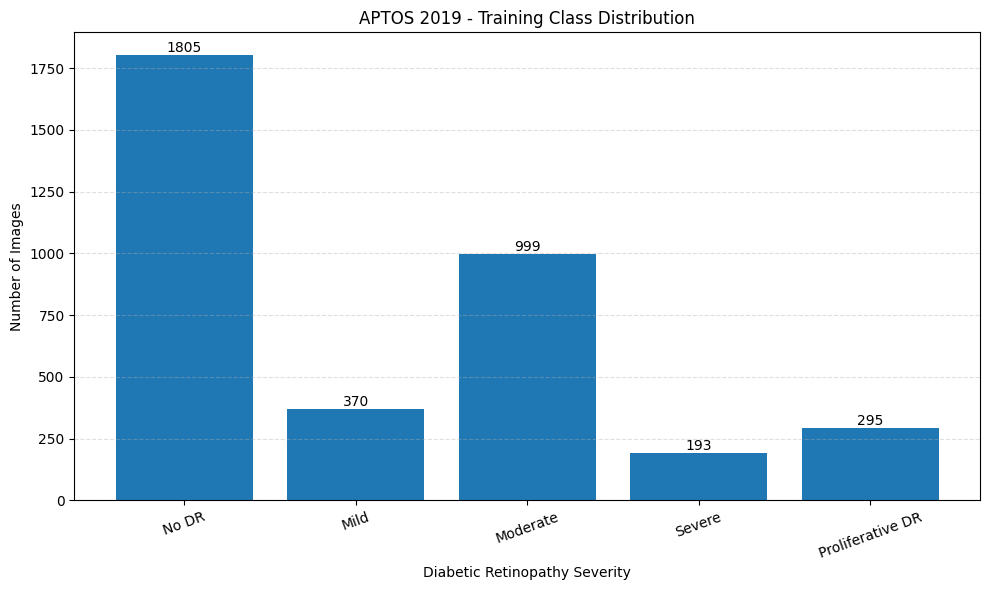

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    class_distribution["Class_Name"],
    class_distribution["Image_Count"]
)

plt.title("APTOS 2019 - Training Class Distribution")
plt.xlabel("Diabetic Retinopathy Severity")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Display image counts above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [5]:
# Get all image files in the training directory
TRAIN_IMAGE_DIR = DATASET_ROOT / "train_images"

image_files = {
    path.stem
    for path in TRAIN_IMAGE_DIR.iterdir()
    if path.is_file()
}

# Compare image filenames against CSV IDs
csv_ids = set(train_df["id_code"])

missing_images = csv_ids - image_files
unmatched_images = image_files - csv_ids

print("Training image validation")
print("-" * 40)
print("Images referenced in train.csv:", len(csv_ids))
print("Image files found:", len(image_files))
print("Missing image files:", len(missing_images))
print("Unmatched image files:", len(unmatched_images))

if missing_images:
    print("\nMissing image IDs (first 10):")
    print(list(missing_images)[:10])

if unmatched_images:
    print("\nUnmatched image IDs (first 10):")
    print(list(unmatched_images)[:10])

Training image validation
----------------------------------------
Images referenced in train.csv: 3662
Image files found: 3662
Missing image files: 0
Unmatched image files: 0


In [6]:
from PIL import Image
from collections import Counter

image_properties = []

for image_path in TRAIN_IMAGE_DIR.iterdir():
    if not image_path.is_file():
        continue

    try:
        with Image.open(image_path) as img:
            image_properties.append({
                "filename": image_path.name,
                "width": img.width,
                "height": img.height,
                "format": img.format,
                "mode": img.mode,
                "size_kb": round(image_path.stat().st_size / 1024, 2)
            })
    except Exception as e:
        print(f"Error reading {image_path.name}: {e}")

image_info_df = pd.DataFrame(image_properties)

print("Total readable images:", len(image_info_df))
print("\nImage formats:")
print(image_info_df["format"].value_counts())

print("\nColor modes:")
print(image_info_df["mode"].value_counts())

print("\nImage dimension statistics:")
display(
    image_info_df[["width", "height", "size_kb"]].describe().round(2)
)

print("\nUnique image dimensions:")
print(
    image_info_df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

print("\nSample image properties:")
display(image_info_df.head())

Total readable images: 3662

Image formats:
format
PNG    3662
Name: count, dtype: int64

Color modes:
mode
RGB    3662
Name: count, dtype: int64

Image dimension statistics:


,width,height,size_kb
count,3662.00,3662.00,3662.00
mean,2015.18,1526.83,2294.22
std,884.30,542.66,1721.14
min,474.00,358.00,216.54
25%,1050.00,1050.00,980.46
50%,2144.00,1536.00,1889.60
75%,2588.00,1958.00,2780.12
max,4288.00,2848.00,7494.43



Unique image dimensions:
width  height
1050   1050      974
2416   1736      638
2588   1958      533
3216   2136      410
2048   1536      351
819    614       287
3388   2588      141
1504   1000       92
1844   1226       61
4288   2848       52
640    480        42
2896   1944       34
2144   1424       28
1476   1117       14
474    358         2
dtype: int64

Sample image properties:


,filename,width,height,format,mode,size_kb
0,ef476be214d4.png,819,614,PNG,RGB,306.81
1,6dcde47060f9.png,3216,2136,PNG,RGB,2225.96
2,ec363f48867b.png,2588,1958,PNG,RGB,5330.03
3,17f6c7072f61.png,1050,1050,PNG,RGB,912.12
4,b49b2fac2514.png,3388,2588,PNG,RGB,6954.03


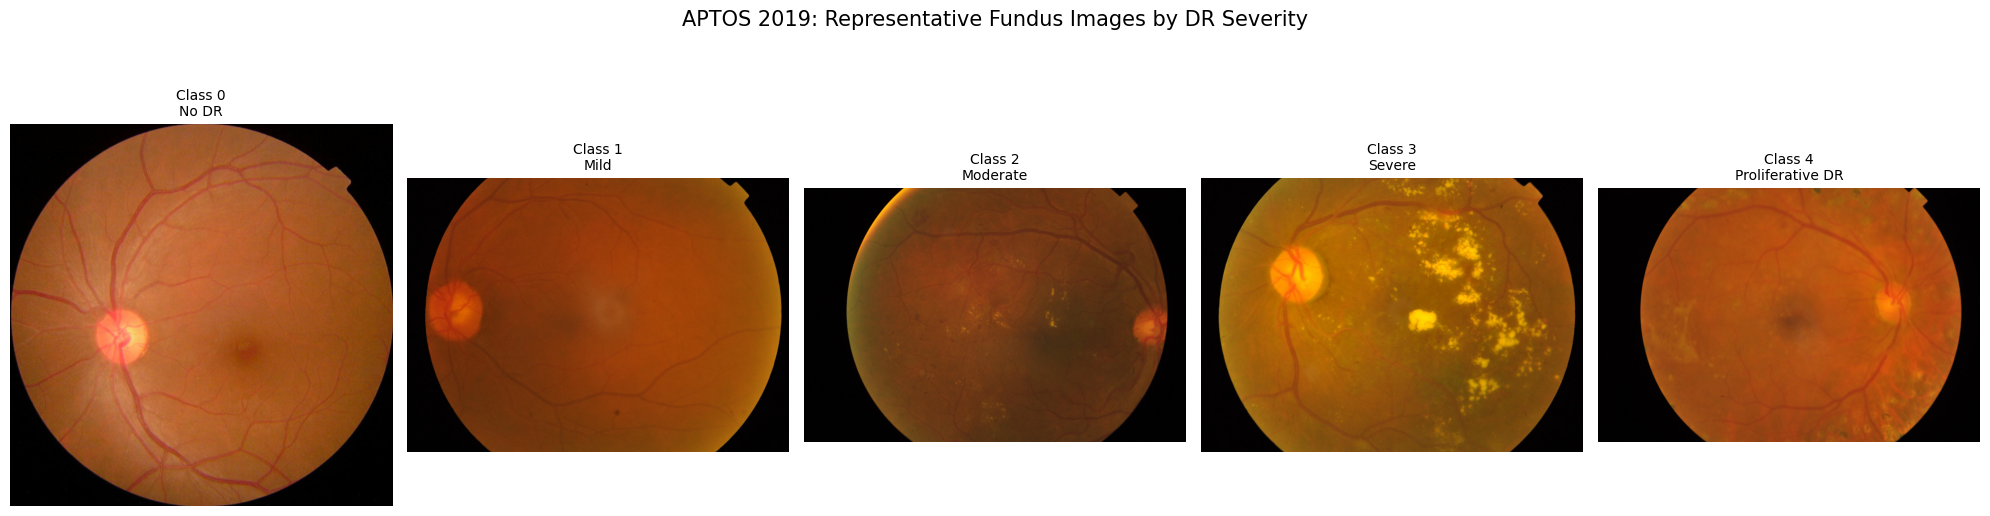

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

class_names = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}

fig, axes = plt.subplots(1, 5, figsize=(20, 6))

for diagnosis in range(5):
    sample_id = train_df.loc[
        train_df["diagnosis"] == diagnosis, "id_code"
    ].iloc[0]

    image_path = TRAIN_IMAGE_DIR / f"{sample_id}.png"

    with Image.open(image_path) as img:
        axes[diagnosis].imshow(img.copy())

    axes[diagnosis].set_title(
        f"Class {diagnosis}\n{class_names[diagnosis]}",
        fontsize=10
    )
    axes[diagnosis].axis("off")

plt.suptitle(
    "APTOS 2019: Representative Fundus Images by DR Severity",
    fontsize=15
)
plt.tight_layout()
plt.show()

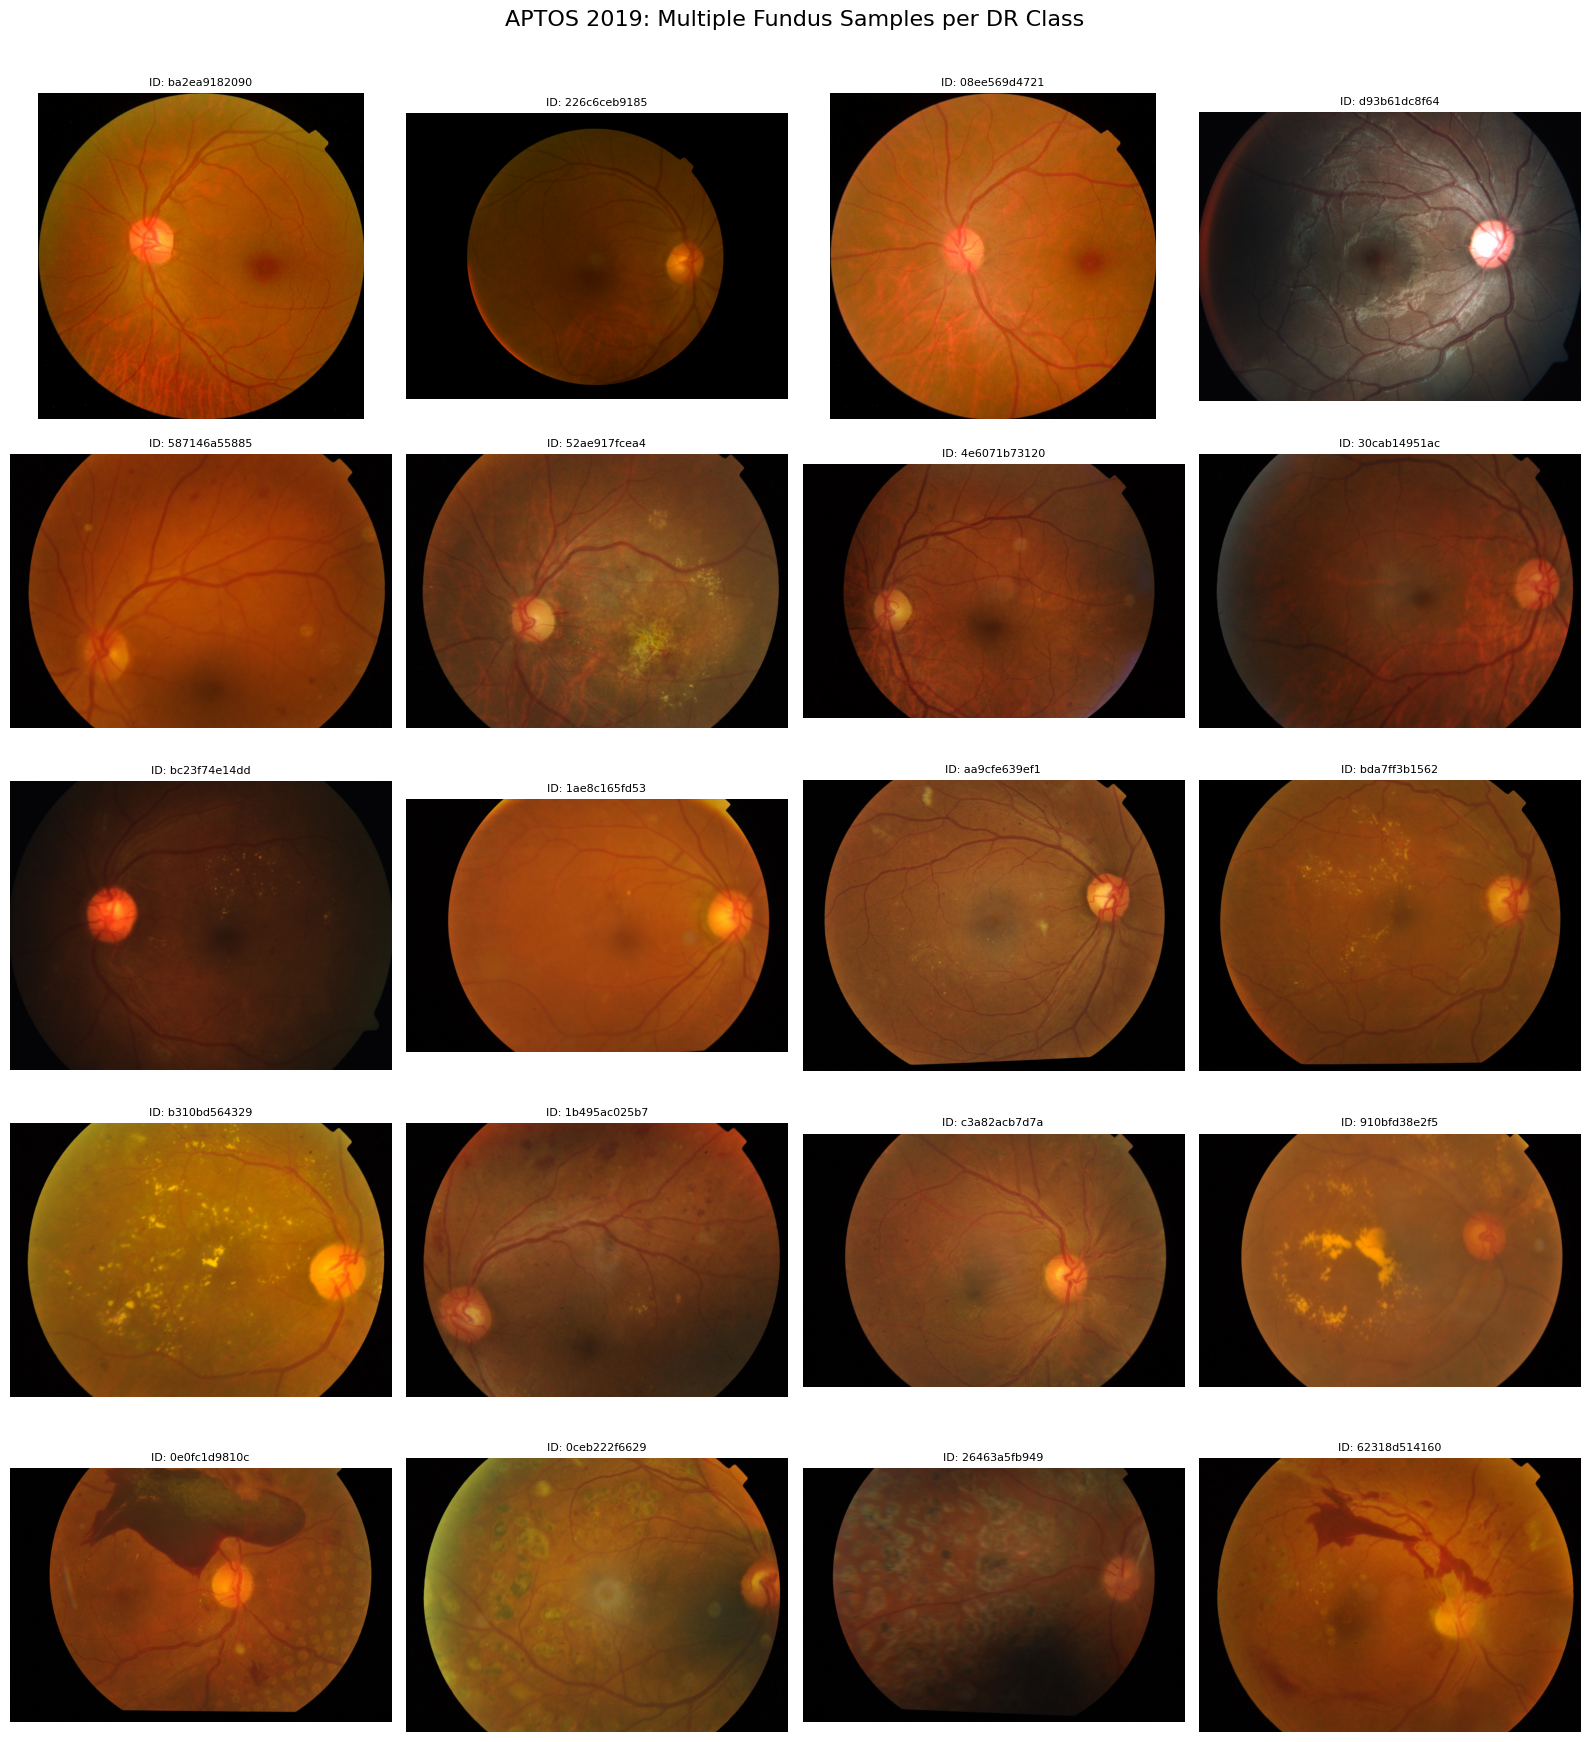

In [8]:
import random
import matplotlib.pyplot as plt
from PIL import Image

# Reproducible random sampling
random.seed(42)

fig, axes = plt.subplots(5, 4, figsize=(16, 18))

for diagnosis in range(5):
    class_samples = train_df[
        train_df["diagnosis"] == diagnosis
    ]["id_code"].tolist()

    selected_ids = random.sample(
        class_samples,
        min(4, len(class_samples))
    )

    for col, sample_id in enumerate(selected_ids):
        image_path = TRAIN_IMAGE_DIR / f"{sample_id}.png"

        with Image.open(image_path) as img:
            axes[diagnosis, col].imshow(img.copy())

        axes[diagnosis, col].set_title(
            f"ID: {sample_id}",
            fontsize=8
        )
        axes[diagnosis, col].axis("off")

    # Label each row with its DR class
    axes[diagnosis, 0].set_ylabel(
        f"Class {diagnosis}\n{class_names[diagnosis]}",
        fontsize=10
    )

plt.suptitle(
    "APTOS 2019: Multiple Fundus Samples per DR Class",
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [9]:
from PIL import Image

corrupted_images = []

for image_path in TRAIN_IMAGE_DIR.iterdir():
    if not image_path.is_file():
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception as e:
        corrupted_images.append({
            "filename": image_path.name,
            "error": str(e)
        })

print("Total images checked:", len(image_files))
print("Corrupted or invalid images:", len(corrupted_images))

if corrupted_images:
    display(pd.DataFrame(corrupted_images).head(20))
else:
    print("All training images passed the integrity check.")

Total images checked: 3662
Corrupted or invalid images: 0
All training images passed the integrity check.


In [10]:
#Meta Data 
print("APTOS 2019 - Data Exploration Summary")
print("-" * 40)
print(f"Training images: {len(train_df)}")
print(f"Number of DR classes: {train_df['diagnosis'].nunique()}")
print(f"Missing labels: {train_df['diagnosis'].isna().sum()}")
print(f"Readable images: {len(image_info_df)}")
print(f"Corrupted images: {len(corrupted_images)}")
print(f"Image formats: {image_info_df['format'].nunique()}")
print(f"Color mode:{image_info_df['mode'][0]}")
print(f"Color modes: {image_info_df['mode'].nunique()}")
print(f"Unique image dimensions: {image_info_df.groupby(['width', 'height']).ngroups}")

print("\nClass distribution:")
display(class_distribution)

APTOS 2019 - Data Exploration Summary
----------------------------------------
Training images: 3662
Number of DR classes: 5
Missing labels: 0
Readable images: 3662
Corrupted images: 0
Image formats: 1
Color mode:RGB
Color modes: 1
Unique image dimensions: 17

Class distribution:


,Diagnosis,Class_Name,Image_Count,Percentage
0,0,No DR,1805,49.29
1,1,Mild,370,10.10
2,2,Moderate,999,27.28
3,3,Severe,193,5.27
4,4,Proliferative DR,295,8.06
